# 01 · Data exploration

What is actually in the SkillCorner basketball open data, measured rather than assumed. Everything below reads the canonical Parquet layer built by `scripts/01_ingest.py`.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config as C
pd.set_option("display.width", 160, "display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110})
E = C.PROCESSED_DIR / "events"; D = C.DERIVED_DIR
rd  = lambda n: pd.read_parquet(D / f"{n}.parquet")
rev = lambda n: pd.read_parquet(E / f"{n}.parquet")
print("project:", C.PROJECT_ROOT.name)

project: basketball-intelligence


## Coverage

In [2]:
games = pd.read_parquet(C.PROCESSED_DIR / "dim/games.parquet")
print(f"{len(games)} games, {games.home_team_id.nunique() + games.away_team_id.nunique()} team slots")
games[["game_id","date","home_team_name","home_score","away_score","away_team_name"]]

10 games, 20 team slots


,game_id,date,home_team_name,home_score,away_score,away_team_name
0,114086,2026-02-08T17:00:00Z,Dreamland Gran Canaria,75,97,Bitci Baskonia
1,114099,2026-01-31T20:00:00Z,Basquet Girona,77,71,San Pablo Burgos
2,114169,2025-12-14T11:30:00Z,CB UCAM Murcia,80,77,Club Joventut Badalona
3,114234,2025-10-18T19:00:00Z,Casademont Zaragoza,84,88,Leche Rio Breogan
4,114243,2025-10-11T19:00:00Z,BAXI Manresa,83,68,Coviran Granada
5,178442,2026-03-21T18:00:00Z,BC MoraBanc Andorra,98,102,Bilbao Basket
6,179612,2026-04-12T10:30:00Z,Malaga,89,96,Valencia BC
7,184439,2026-04-19T17:00:00Z,Real Madrid,90,95,Lenovo Tenerife
8,188630,2026-05-03T17:00:00Z,BC Barcelona,91,69,Dreamland Gran Canaria
9,191313,2026-05-29T18:30:00Z,Leche Rio Breogan,94,95,Casademont Zaragoza


## Event volume by family

Twenty tables, four orders of magnitude apart in size.

total event rows: 71,984


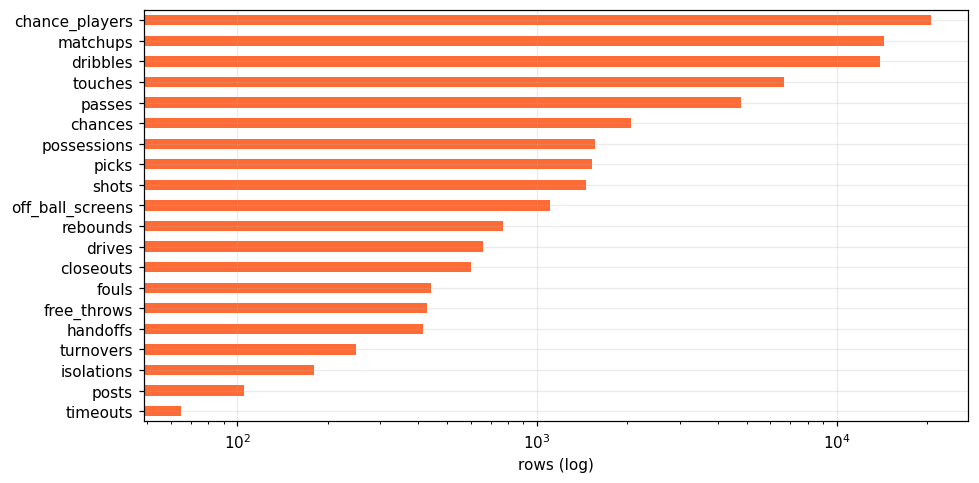

,rows
timeouts,65
posts,105
isolations,180
turnovers,248
handoffs,417
free_throws,430
fouls,443
closeouts,601
drives,660
rebounds,768


In [3]:
rows = {p.stem: len(pd.read_parquet(p, columns=["id"])) for p in sorted(E.glob("*.parquet"))}
s = pd.Series(rows).sort_values()
print("total event rows:", f"{s.sum():,}")
ax = s.plot.barh(color="#FF6B35", logx=True); ax.set_xlabel("rows (log)"); plt.tight_layout(); plt.show()
s.to_frame("rows")

## The chance is the analytic unit

A possession can contain several chances (offensive rebounds). Per-chance is the right denominator for efficiency.

In [4]:
ch, po = rev("chances"), rev("possessions")
print(f"{len(po):,} possessions -> {len(ch):,} chances  ({len(ch)/len(po):.2f} chances per possession)")
print("\npoints per chance:", round(ch.pts_scored.mean(), 3))
print("\nchances per possession:"); print(ch.groupby("possession_id").size().value_counts().sort_index())
print("\nhow chances start:"); print(ch.start_type.value_counts())
print("\nhow chances end:"); print(ch.outcome.value_counts())

1,564 possessions -> 2,055 chances  (1.31 chances per possession)

points per chance: 0.836

chances per possession:
1    1184
2     295
3      65
4      14
5       6
Name: count, dtype: int64

how chances start:
start_type
DEFOB    549
FGM      487
FGDRB    462
FGORB    180
FTM      172
TO       143
FTDRB     44
JMP       11
FTORB      7
Name: count, dtype: int64

how chances end:
outcome
FOU              417
FGM              396
FGX              388
FGX3             340
TO               250
FGM3             176
Out of Bounds     68
EPD               20
Name: count, dtype: int64


## Score reconciliation

The first thing to check on any event feed: do the events reproduce the official score? All ten games, exactly.

In [5]:
sh, ft = rev("shots"), rev("free_throws")
pts = (sh[sh.outcome].assign(p=np.where(sh[sh.outcome].three, 3, 2))
         .groupby(["game_id","off_team_id"]).p.sum()
         .add(ft[ft.outcome].groupby(["game_id","off_team_id"]).size(), fill_value=0))
chk = [{"game": g.game_id,
        "home_calc": int(pts.get((g.game_id, g.home_team_id), 0)), "home_official": g.home_score,
        "away_calc": int(pts.get((g.game_id, g.away_team_id), 0)), "away_official": g.away_score}
       for g in games.itertuples(index=False)]
chk = pd.DataFrame(chk)
chk["match"] = (chk.home_calc == chk.home_official) & (chk.away_calc == chk.away_official)
print("all games reconcile:", chk.match.all()); chk

all games reconcile: True


,game,home_calc,home_official,away_calc,away_official,match
0,114086,75,75,97,97,True
1,114099,77,77,71,71,True
2,114169,80,80,77,77,True
3,114234,84,84,88,88,True
4,114243,83,83,68,68,True
5,178442,98,98,102,102,True
6,179612,89,89,96,96,True
7,184439,90,90,95,95,True
8,188630,91,91,69,69,True
9,191313,94,94,95,95,True


## Enum vocabularies, as delivered

No coverage or contest label in this project is invented; these are the exact value sets in the data.

In [6]:
pk, dr = rev("picks"), rev("drives")
for lbl, s in [("shots.contest_level", sh.contest_level), ("shots.shot_type", sh.shot_type),
               ("picks.bhr_def_type", pk.bhr_def_type), ("picks.scr_def_type", pk.scr_def_type),
               ("drives.category", dr.category), ("drives.end_type", dr.end_type)]:
    print(f"{lbl:24s} {dict(s.value_counts())}")

shots.contest_level      {'plus': np.int64(593), 'average': np.int64(395), 'open': np.int64(301), 'light': np.int64(93), 'blocked': np.int64(51)}
shots.shot_type          {'jumper': np.int64(691), 'layup': np.int64(577), 'post': np.int64(85), 'floater': np.int64(71), 'heave': np.int64(9)}
picks.bhr_def_type       {'over': np.int64(1004), 'under': np.int64(280), 'switch': np.int64(218), 'ice': np.int64(14), 'blitz': np.int64(4)}
picks.scr_def_type       {'soft': np.int64(663), 'show': np.int64(615), 'switch': np.int64(218), 'ice': np.int64(14), 'none': np.int64(6), 'blitz': np.int64(4)}
drives.category          {'pick': np.int64(332), 'closeout': np.int64(111), 'miscellaneous': np.int64(76), 'iso': np.int64(75), 'handoff': np.int64(47), 'offBallScreen': np.int64(19)}
drives.end_type          {'shotNearBasket': np.int64(246), 'kickout': np.int64(184), 'pullup': np.int64(96), 'interiorPass': np.int64(64), 'stoppage': np.int64(29), 'turnover': np.int64(28), 'pullout': np.int64(13)}


## Missingness

Where the feed is incomplete, and by how much.

In [7]:
miss = (sh[["location_x","closest_def_dist","shot_quality","release_time",
             "dribbles_before","passer_id","touch_id"]].isna().mean()*100).round(2)
print("shots — % null:"); print(miss)
print("\nfouled shots (excluded from box-score FGA):", int(sh.fouled.sum()),
      "of", len(sh), f"({sh.fouled.mean():.1%})")

shots — % null:
location_x           1.78
closest_def_dist     1.78
shot_quality         1.78
release_time         5.62
dribbles_before      5.55
passer_id           12.27
touch_id             5.55
dtype: float64

fouled shots (excluded from box-score FGA): 143 of 1459 (9.8%)
